In [1]:
import pandas as pd
import matplotlib.pyplot as plt

raw = pd.read_csv("../data/raw/netflix_titles.csv")
clean = pd.read_csv("../data/processed/netflix_titles_clean.csv", parse_dates=["date_added"])

print("Raw shape:  ", raw.shape)
print("Clean shape:", clean.shape)

Raw shape:   (8807, 12)
Clean shape: (8807, 18)


In [2]:
cols = ["director", "cast", "country", "date_added", "rating", "duration"]

comparison = pd.DataFrame({
    "missing_before": raw[cols].isnull().sum(),
    "missing_after": clean[cols].isnull().sum(),
    "filled_with_Unknown": clean[cols].astype(str).eq("Unknown").sum(),
})
comparison["pct_missing_before"] = (comparison["missing_before"] / len(raw) * 100).round(1)
comparison

,missing_before,missing_after,filled_with_Unknown,pct_missing_before
director,2634,0,2634,29.9
cast,825,0,825,9.4
country,831,0,831,9.4
date_added,10,10,0,0.1
rating,4,7,0,0.0
duration,3,0,0,0.0


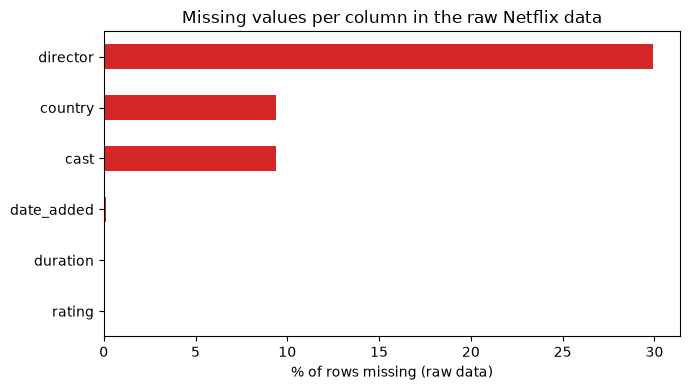

In [3]:
ax = comparison["pct_missing_before"].sort_values().plot(kind="barh", color="tab:red", figsize=(7, 4))
ax.set_xlabel("% of rows missing (raw data)")
ax.set_title("Missing values per column in the raw Netflix data")
plt.tight_layout()
plt.savefig("../reports/missing_values_raw.png", dpi=150)
plt.show()

In [4]:
facts = pd.DataFrame({
    "dtype": clean.dtypes.astype(str),
    "missing": clean.isnull().sum(),
    "unique_values": clean.nunique(),
})
facts["missing_pct"] = (facts["missing"] / len(clean) * 100).round(2)
facts

,dtype,missing,unique_values,missing_pct
show_id,str,0,8807,0.00
type,str,0,2,0.00
title,str,0,8806,0.00
director,str,0,4529,0.00
cast,str,0,7693,0.00
country,str,0,749,0.00
date_added,datetime64[us],10,1714,0.11
release_year,int64,0,74,0.00
rating,str,7,13,0.08
duration,str,0,220,0.00
